# Paired class imbalance and branch outcomes

How does changing the population class prior affect dynamic configuration formation, subsequent fitting within a frozen objective, and finite-horizon attraction? This notebook compares
\[
p\in\left\{\tfrac12,\frac{1/2+p_c}{2},p_c\right\},\qquad p_c=0.2,
\]
using the existing collapse setting's dimensions, sample sizes, signal scale, noise, raw thresholds, \(\pi\), ridge, step size, and initialization protocol. It does not tune parameters or filter runs according to the desired outcome. Balanced classes are allowed to collapse.

The cache is produced by [the additive runner](../../../../experiments/confirmation_bias/runner.py). Notebook [15](15_checkpoint_branch_consistency.ipynb) gives the full model, fixed-\(M\) objectives, update identities, and unconstrained minimizer diagnostics. Mathematical source: the supplied *Mean Field Dynamics of Self Training via Gradient Descent*, section 7. All outcome statements below are generated from executed results.

## Paired data construction and estimands

For each seed, construct one shared signal \(\mu\), Gaussian noise array \((U_i)\), labeled/unlabeled membership, and continuous class-assignment ranks. Within each subset, assign \(+1\) to the lowest-ranked observations up to the prescribed class count, using nearest-integer rounding (ties to even). Labeled counts are clipped to \([1,N-1]\) so both classes remain present. Assignments are nested across the three priors. The feature array is reconstructed after each assignment:
\[
X_i(p)=Y_i(p)\mu/\sqrt d+\sigma U_i.
\]
Changing labels while keeping their old features would violate the model and is not done. Population \(p\) and both realized subset proportions are reported separately. Exact prescribed training counts replace the legacy iid sample-cell draw; the analytic population distribution still has prior \(p\).

Independent reproducible streams govern parameter draws, noise, membership, ranks, and initial pseudo-labels. Each dataset uses the same initialization **procedure**: \(b^0=0\), independent Gaussian \(w^0\), and exogenous Rademacher unlabeled initial targets, with labeled entries reset to the current dataset's labels. This procedure is data-independent in the present setting; its random inputs are paired. The engine's exceptional \(t=0\) update is preserved.

All unlabeled objectives use fixed denominator \(M\), with `normalize_unlabeled_loss=False`. \(\pi\) multiplies the unlabeled objective and remains separate from the logged update component \(\zeta_U\). Selection uses raw scores, inclusive threshold equality, and the sign convention \(\operatorname{sign}(0)=+1\).

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
# Embed figures in the notebook even under a headless runner.
get_ipython().run_line_magic("matplotlib", "inline")
from matplotlib import pyplot as plt
from IPython.display import Markdown, display

HERE = Path.cwd().resolve()
ROOT = next((path for path in (HERE, *HERE.parents)
             if (path / "src").is_dir() and (path / "experiments" / "confirmation_bias").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or its notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from experiments.confirmation_bias.config import preset
from experiments.confirmation_bias.runner import load_suite
from experiments.confirmation_bias import reporting as report

pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 85)

In [2]:
PROFILE = os.environ.get("CONFIRMATION_PROFILE", "smoke")  # smoke | pilot | expanded
ALLOW_RUN = False  # opt-in only; opening/executing never starts a missing sweep by default
CONFIG = preset(PROFILE)
OUTPUT_ROOT = ROOT / "outputs" / "confirmation_bias"
print(f"Profile={PROFILE}; seeds={CONFIG.seeds}; d={CONFIG.d}; N={CONFIG.n_labeled}; "
      f"M={CONFIG.n_unlabeled}; T={CONFIG.T}; priors={CONFIG.imbalance_levels}")

Profile=smoke; seeds=(49,); d=32; N=8; M=120; T=12; priors=(0.5, 0.35, 0.2)


## Load a compatible result set

The default `smoke` profile is an execution check. The substantive `pilot` uses three reproducible seeds; `expanded` uses ten. Execute the runner explicitly before changing profiles. Loading does not retrain, and incompatible configurations use different cache identifiers. Regenerated figures and tables are written only within this suite's output directory.

In [3]:
if ALLOW_RUN:
    # Explicit user opt-in. Cached results are reused by the runner.
    import subprocess
    subprocess.run([sys.executable, "-m", "experiments.confirmation_bias.runner",
                    "--profile", PROFILE, "--output-root", str(OUTPUT_ROOT)],
                   cwd=ROOT, check=True)
try:
    suite = load_suite(CONFIG, output_root=OUTPUT_ROOT)
except FileNotFoundError as exc:
    raise RuntimeError(
        f"No compatible {PROFILE} cache. Run from the repository root:\n"
        f"PYTHONPATH=. python3 -m experiments.confirmation_bias.runner --profile {PROFILE}\n"
        "Then execute this notebook again. Full runs are deliberately opt-in."
    ) from exc

tables = report.export_tables(suite)
print("Cache:", suite["output_dir"])
display(pd.DataFrame([suite["config"]]))
display(suite["metadata"])
if PROFILE == "smoke":
    display(Markdown("**Validation profile:** reduced dimensions and horizon. Smoke outputs are not evidence for the scientific collapse hypothesis."))

Cache: /Users/thierryrioual/Desktop/Princeton/Academics/Research/implementation/outputs/confirmation_bias/smoke-edce8d87002d52a9


,d,n_labeled,n_unlabeled,T,p_c,sigma,signal_std,eta,penalty,...,profile,solver_gtol,solver_ftol,solver_maxiter,solver_maxls,solver_residual_tolerance,consistency_tolerance,deterioration_tolerance,replay_tolerance
0,32,8,120,12,0.2,1.0,1.0,0.5,0.1,...,smoke,1.000000e-08,1.000000e-15,1500,40,0.000001,1.000000e-07,1.000000e-08,1.000000e-10


{'configuration_id': 'smoke-edce8d87002d52a9',
 'schema_version': 1,
 'config': {'d': 32,
  'n_labeled': 8,
  'n_unlabeled': 120,
  'T': 12,
  'p_c': 0.2,
  'sigma': 1.0,
  'signal_std': 1.0,
  'eta': 0.5,
  'penalty': 0.1,
  'pi': 2.0,
  'kappa_minus': -1.3862943611198906,
  'kappa_plus': 1.3862943611198906,
  'seeds': [49],
  'profile': 'smoke',
  'solver_gtol': 1e-08,
  'solver_ftol': 1e-15,
  'solver_maxiter': 1500,
  'solver_maxls': 40,
  'solver_residual_tolerance': 1e-06,
  'consistency_tolerance': 1e-07,
  'deterioration_tolerance': 1e-08,
  'replay_tolerance': 1e-10},
 'software': {'python': '3.9.6 (default, Apr 30 2025, 02:07:17) \n[Clang 17.0.0 (clang-1700.0.13.5)]',
  'platform': 'macOS-26.6.2-arm64-arm-64bit',
  'numpy': '2.0.2',
  'scipy': '1.13.1',
  'torch': '2.8.0',
  'git_commit': 'c0b35e69887b814535424ebaeafc43adbf84427b',
  'git_status': 'M .DS_Store\n M .gitignore\n M notebooks/14_unlabeled_loss_normalization.ipynb\n?? .Rhistory\n?? experiments/\n?? outputs/\n?? sc

**Validation profile:** reduced dimensions and horizon. Smoke outputs are not evidence for the scientific collapse hypothesis.

In [4]:
baselines = tables["baselines"]
columns = ["seed", "p", "data_realized_labeled_p", "data_realized_unlabeled_p",
           "t_best", "best_error", "terminal_error", "deterioration", "deteriorated"]
display(baselines[[column for column in columns if column in baselines]])
# Exact hashes/stream metadata are retained per run for auditing the latent pairing.
for run in report.select_runs(suite):
    print(f"seed={run['seed']}, p={run['p']}: {run['data_metadata'].get('pairing')}")

,seed,p,data_realized_labeled_p,data_realized_unlabeled_p,t_best,best_error,terminal_error,deterioration,deteriorated
0,49,0.50,0.500,0.50,12,0.239061,0.239061,0.0,False
1,49,0.35,0.375,0.35,12,0.291541,0.291541,0.0,False
2,49,0.20,0.250,0.20,12,0.222171,0.222171,0.0,False


seed=49, p=0.5: shared mu,U,Delta,class ranks,w_init,and exogenous unlabeled Y_init
seed=49, p=0.35: shared mu,U,Delta,class ranks,w_init,and exogenous unlabeled Y_init
seed=49, p=0.2: shared mu,U,Delta,class ranks,w_init,and exogenous unlabeled Y_init


## Absolute-iteration comparisons: every seed and descriptive means

The error is the exact Gaussian population error conditional on each fitted parameter; it is not a test-set estimate. Curves are aligned by **absolute iteration**. The plots retain every seed and show an unweighted seed mean where multiple seeds are available. Means, minima, and maxima are descriptive summaries; three seeds do not support reliable inferential uncertainty estimates.

Changing \(p\) changes both the training labels/features and the population error functional. A paired terminal-error difference is therefore a comparison of the two specified settings, not a pure effect on optimization with a common evaluation distribution. Pairing reduces unrelated simulation variation without making these estimands identical.

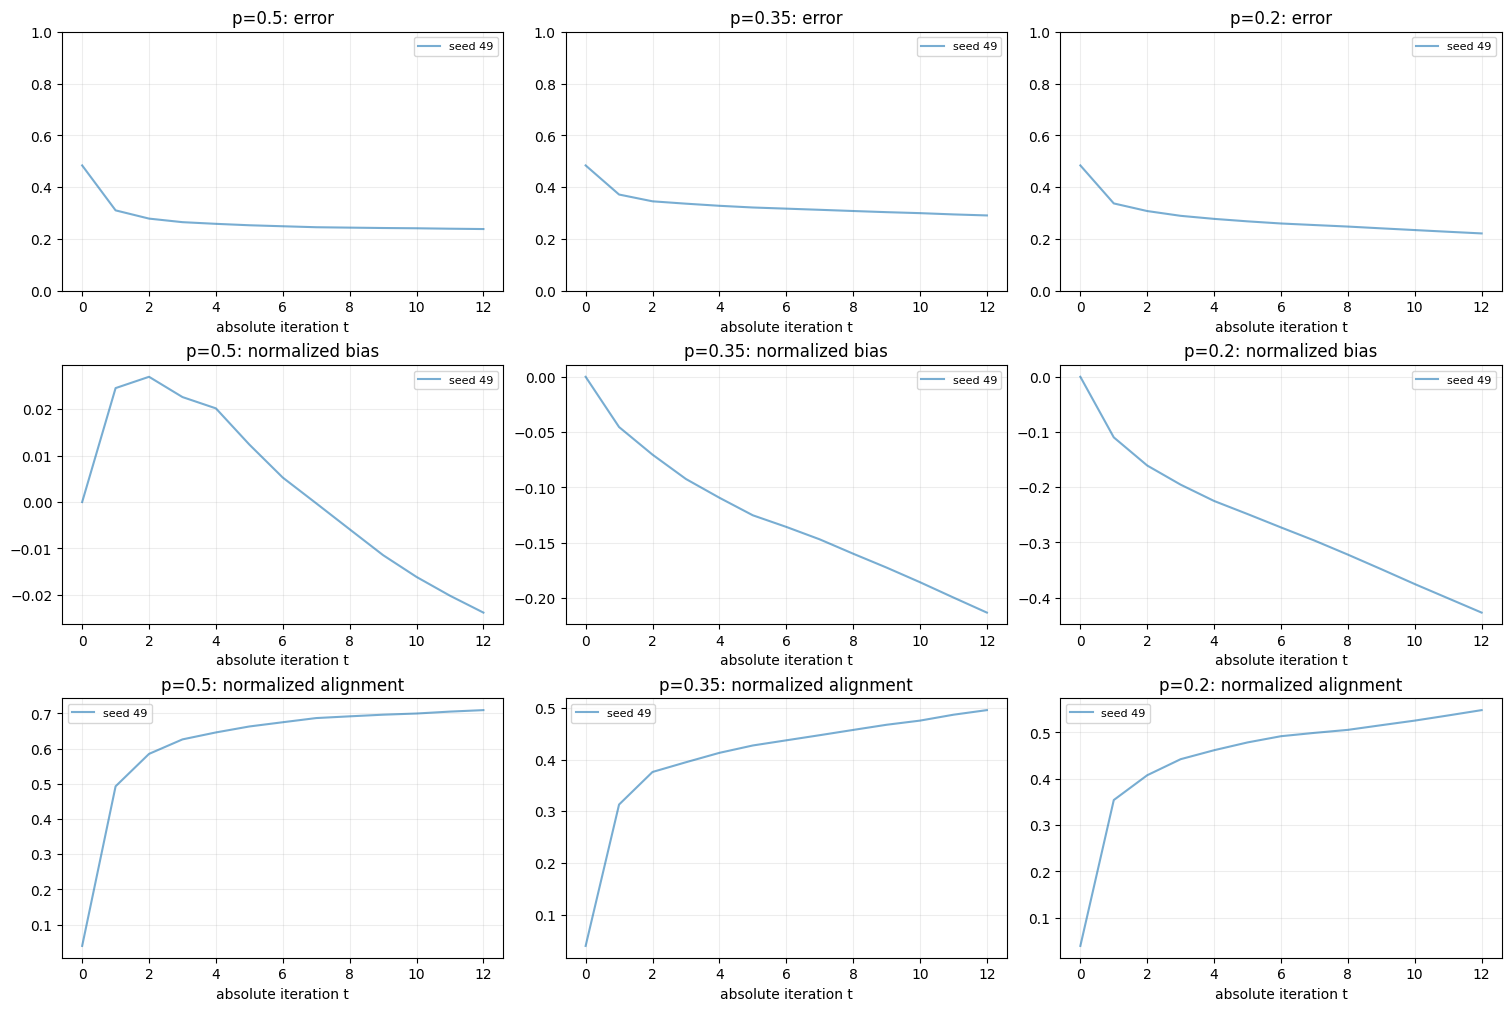

,p,seeds,terminal_error_mean,terminal_error_min,terminal_error_max,deterioration_mean,deteriorated_runs,terminal_zero_fraction_mean
0,0.50,1,0.239061,0.239061,0.239061,0.0,0,0.500
1,0.35,1,0.291541,0.291541,0.291541,0.0,0,0.600
2,0.20,1,0.222171,0.222171,0.222171,0.0,0,0.525


,seed,p,reference_p,terminal_error_minus_reference,best_error_minus_reference,deterioration_minus_reference
0,49,0.35,0.5,0.05248,0.05248,0.0
1,49,0.20,0.5,-0.01689,-0.01689,0.0


In [5]:
fig = report.plot_imbalance_baselines(suite)
report.save_figure(suite, fig, "16_imbalance_absolute_trajectories")
display(fig)
plt.close(fig)
display(tables["imbalance_aggregates"])
display(tables["paired_differences"])

## Checkpoint-relative comparisons remain within each trajectory

Each run selects its own earliest post-initial minimum-error checkpoint. The next plots align by \(t-t_{\rm best}\), so the origins can correspond to different absolute iterations, parameter states, and selected sets. Remaining horizons can differ. These panels display **individual seeds**, without averaging incomparable checkpoint states or horizons.

Within each run, dynamic, frozen, and selected-oracle continuations share exactly the same checkpoint and remaining horizon. Between priors, the checkpoint itself is an outcome. Therefore, cross-prior checkpoint comparisons are descriptive and conditional; the paired-difference table above instead uses the common terminal absolute iteration \(T\).

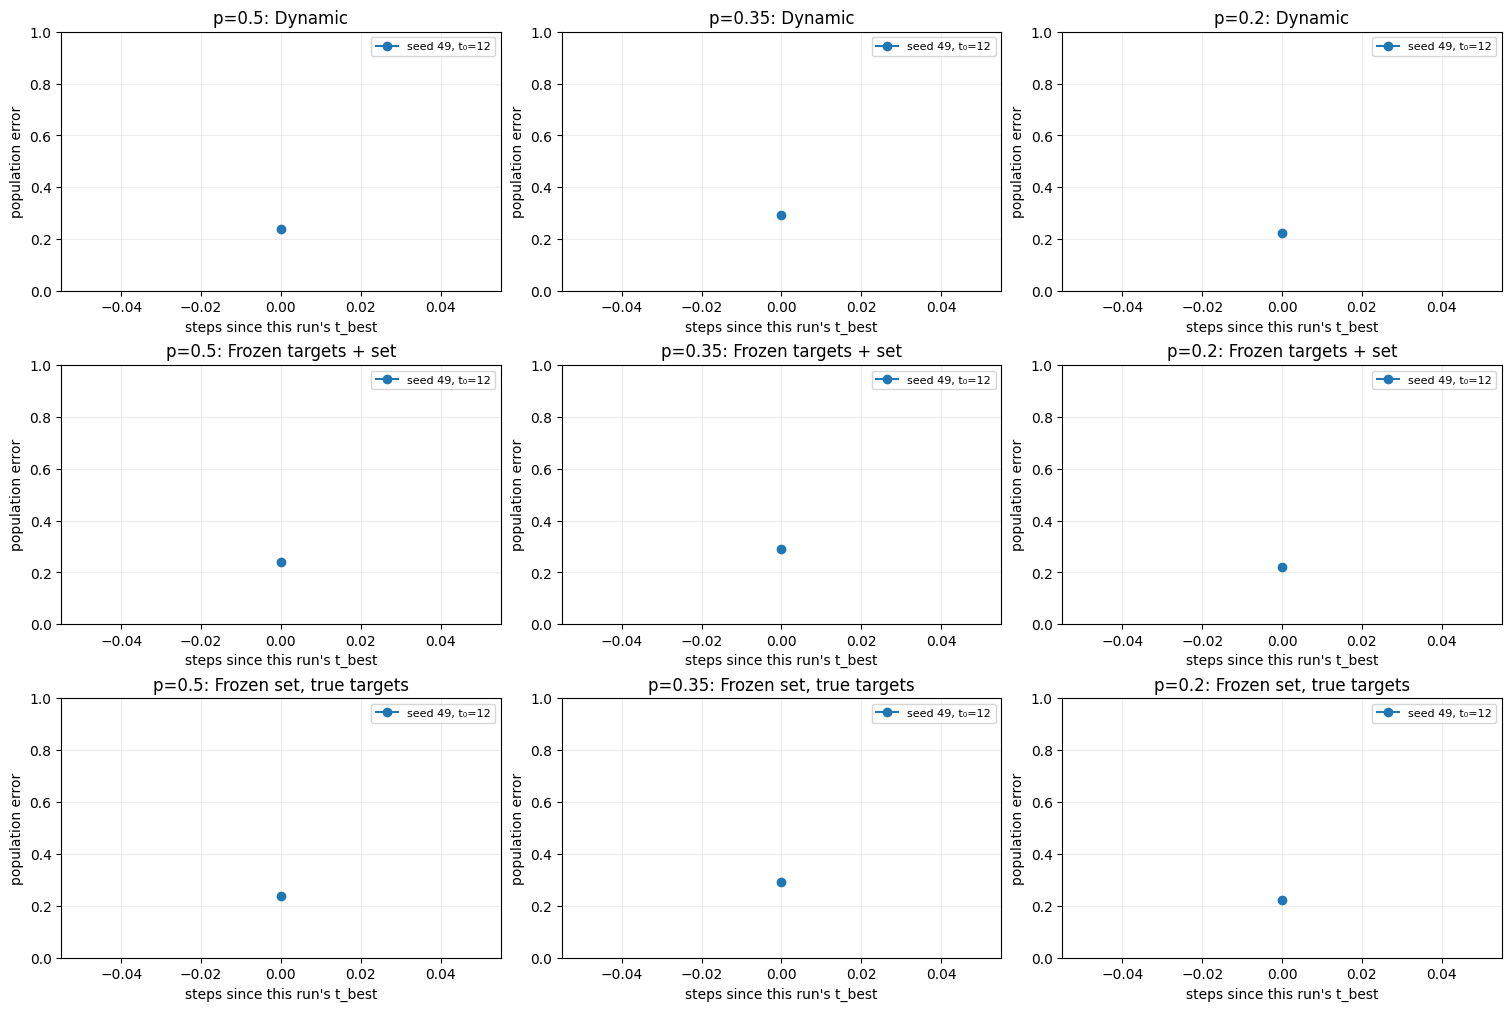

,seed,p,t0,branch,checkpoint_error,terminal_error,error_change_from_checkpoint,terminal_configuration_type,replay_max_abs
0,49,0.50,6,dynamic,0.249810,0.239061,-0.010749,both selected signs plus zeros,0.0
1,49,0.50,6,frozen,0.249810,0.238059,-0.011751,both selected signs plus zeros,0.0
2,49,0.50,6,oracle,0.249810,0.194833,-0.054977,both selected signs plus zeros,0.0
3,49,0.50,12,dynamic,0.239061,0.239061,0.000000,both selected signs plus zeros,0.0
4,49,0.50,12,frozen,0.239061,0.239061,0.000000,both selected signs plus zeros,0.0
5,49,0.50,12,oracle,0.239061,0.239061,0.000000,both selected signs plus zeros,0.0
6,49,0.35,6,dynamic,0.317691,0.291541,-0.026150,both selected signs plus zeros,0.0
7,49,0.35,6,frozen,0.317691,0.301231,-0.016460,both selected signs plus zeros,0.0
8,49,0.35,6,oracle,0.317691,0.220201,-0.097490,both selected signs plus zeros,0.0
9,49,0.35,12,dynamic,0.291541,0.291541,0.000000,both selected signs plus zeros,0.0


In [6]:
fig = report.plot_imbalance_continuations(suite)
report.save_figure(suite, fig, "16_imbalance_checkpoint_relative")
display(fig)
plt.close(fig)
display(tables["continuations"][["seed", "p", "t0", "branch", "checkpoint_error", "terminal_error",
                                  "error_change_from_checkpoint", "terminal_configuration_type", "replay_max_abs"]])

## Configuration outcomes and unconstrained branch minima

A **fully negative-selected** configuration has every unlabeled entry equal to \(-1\). A negative-selected configuration **plus zeros** is different: some observations remain excluded. The analogous distinction holds for positive-selected configurations. An all-unselected configuration and configurations with both selected signs are retained as separate categories. Prediction signs are also distinct from configuration signs: an excluded observation still receives a classification prediction.

For each checkpoint, the optimizer minimizes the frozen pseudo-label objective without enforcing its branch inequalities. The minimum signed consistency margin checks selected signs and excluded observations alike. A marker with an insufficient solver residual must not be interpreted as a consistent/inconsistent branch minimum. The detailed status table supplies the tolerance-based classification, raw violations, optimizer status, objective, and gradient residual in \((b,w/\sqrt d)\) coordinates. Numerical strict consistency is not a rigorous optimization-error certificate and is not, by itself, a claim about attraction.

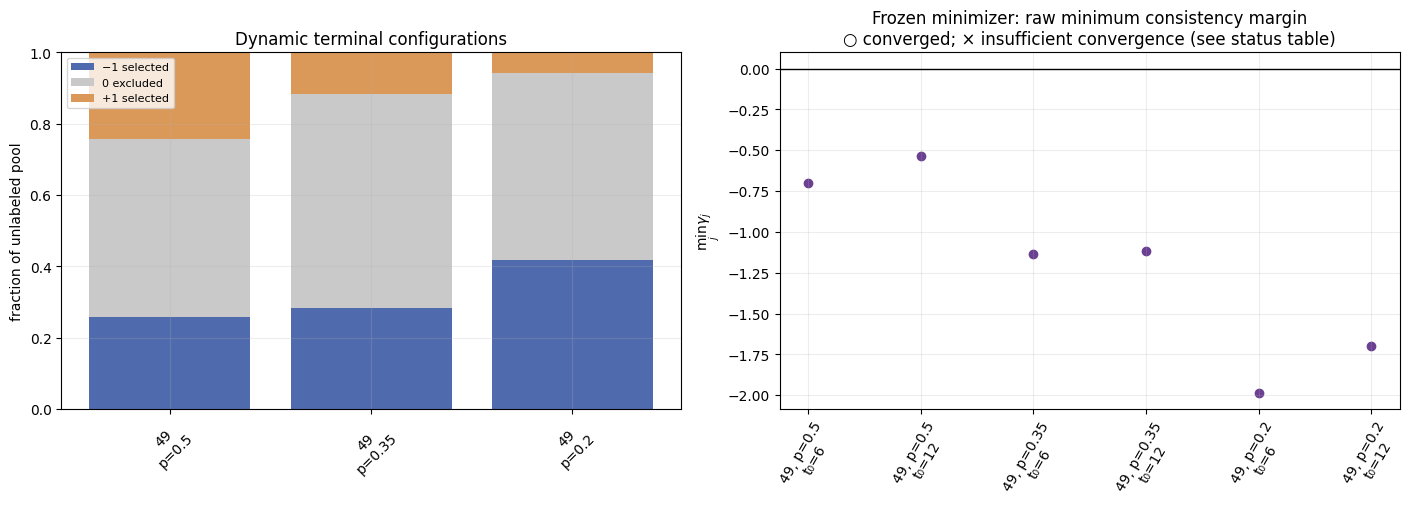

,seed,p,terminal_configuration_type,terminal_minus_fraction,terminal_zero_fraction,terminal_plus_fraction,first_fully_negative_selected_iteration,last_observed_switch
0,49,0.50,both selected signs plus zeros,0.258333,0.500,0.241667,None,10
1,49,0.35,both selected signs plus zeros,0.283333,0.600,0.116667,None,11
2,49,0.20,both selected signs plus zeros,0.416667,0.525,0.058333,None,12


,seed,p,t0,branch,objective,error,gradient_inf,converged,nit,consistency_status,margin_min,n_violated_inequalities
0,49,0.50,6,frozen,0.227441,0.231376,3.814004e-09,True,16,numerically inconsistent,-0.697681,12
1,49,0.50,6,oracle,0.370359,0.202860,9.964078e-09,True,21,numerically inconsistent,-2.417508,40
2,49,0.50,12,frozen,0.246714,0.232684,1.974141e-09,True,16,numerically inconsistent,-0.536700,9
3,49,0.50,12,oracle,0.390411,0.210097,8.363860e-09,True,21,numerically inconsistent,-2.890800,38
4,49,0.35,6,frozen,0.211067,0.275312,6.151360e-09,True,17,numerically inconsistent,-1.136986,26
5,49,0.35,6,oracle,0.359937,0.206496,4.207760e-09,True,23,numerically inconsistent,-3.474470,57
6,49,0.35,12,frozen,0.224257,0.263176,5.035682e-09,True,17,numerically inconsistent,-1.118462,23
7,49,0.35,12,oracle,0.400221,0.225791,3.765428e-09,True,23,numerically inconsistent,-3.542427,47
8,49,0.20,6,frozen,0.184167,0.189314,4.107144e-09,True,16,numerically inconsistent,-1.985749,52
9,49,0.20,6,oracle,0.212061,0.160713,5.676638e-09,True,18,numerically inconsistent,-4.423897,67


,seed,p,t0,branch,message,solver_settings,warnings
0,49,0.50,6,frozen,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
1,49,0.50,6,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
2,49,0.50,12,frozen,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
3,49,0.50,12,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
4,49,0.35,6,frozen,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
5,49,0.35,6,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
6,49,0.35,12,frozen,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
7,49,0.35,12,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
8,49,0.20,6,frozen,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]
9,49,0.20,6,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...",[]


In [7]:
fig = report.plot_branch_outcomes(suite)
report.save_figure(suite, fig, "16_terminal_configurations_and_margins")
display(fig)
plt.close(fig)
display(baselines[["seed", "p", "terminal_configuration_type", "terminal_minus_fraction", "terminal_zero_fraction",
                   "terminal_plus_fraction", "first_fully_negative_selected_iteration", "last_observed_switch"]])
minimizers = tables["minimizers"]
display(minimizers[["seed", "p", "t0", "branch", "objective", "error", "gradient_inf", "converged",
                    "nit", "consistency_status", "margin_min", "n_violated_inequalities"]])
display(minimizers[["seed", "p", "t0", "branch", "message", "solver_settings", "warnings"]])

## Paired within-checkpoint contrasts

For a fixed checkpoint, \(\mathcal E_T^{\rm frozen}-\mathcal E_{t_0}\) measures deterioration during fixed-configuration fitting. \(\mathcal E_T^{\rm dynamic}-\mathcal E_T^{\rm frozen}\) compares allowing configuration changes with freezing them. \(\mathcal E_T^{\rm frozen}-\mathcal E_T^{\rm oracle}\) compares assigned versus correct labels on the identical selected set. The oracle terminal error also records poor outcomes that persist with correct selected labels. These are distinct finite-horizon counterfactual contrasts, not a complete causal decomposition. A frozen minimizer may lie outside its fitted branch, and an oracle minimizer need not be a self-training equilibrium.

In [8]:
contrasts = tables["continuations"].pivot(index=["seed", "p", "t0", "checkpoint_error"],
                                              columns="branch", values="terminal_error").reset_index()
contrasts["frozen_change_from_checkpoint"] = contrasts["frozen"] - contrasts["checkpoint_error"]
contrasts["dynamic_minus_frozen"] = contrasts["dynamic"] - contrasts["frozen"]
contrasts["frozen_minus_oracle"] = contrasts["frozen"] - contrasts["oracle"]
contrasts.to_csv(Path(suite["output_dir"]) / "tables" / "within_checkpoint_contrasts.csv", index=False)
display(contrasts)

branch,seed,p,t0,checkpoint_error,dynamic,frozen,oracle,frozen_change_from_checkpoint,dynamic_minus_frozen,frozen_minus_oracle
0,49,0.20,6,0.260479,0.222171,0.235989,0.178626,-0.024490,-0.013818,0.057363
1,49,0.20,12,0.222171,0.222171,0.222171,0.222171,0.000000,0.000000,0.000000
2,49,0.35,6,0.317691,0.291541,0.301231,0.220201,-0.016460,-0.009691,0.081030
3,49,0.35,12,0.291541,0.291541,0.291541,0.291541,0.000000,0.000000,0.000000
4,49,0.50,6,0.249810,0.239061,0.238059,0.194833,-0.011751,0.001002,0.043225
5,49,0.50,12,0.239061,0.239061,0.239061,0.239061,0.000000,0.000000,0.000000


## Interpretation and limits from the executed results

Configuration formation is observed through dynamic transitions and threshold recruitment. Fitting a given configuration is probed by its frozen continuation and independent minimization. Attraction is only probed along the finite trajectories from the selected states. A long switch-free interval does not prove the configuration remains fixed forever; no local stability spectrum, exhaustive basin analysis, or global convergence theorem is inferred.

The descriptive prior comparisons below preserve all seeds, including balanced collapse, lack of deterioration, reversed oracle contrasts, near-boundary classifications, and failed solves if they occur. Prescribed class counts condition the training design, retrospective checkpoints condition the interventions, and comparisons across priors change the population risk functional. Broader claims require additional justified analysis.

In [9]:
display(Markdown(report.imbalance_interpretation(suite)))
print("Exported figures:", Path(suite["output_dir"]) / "figures")
print("Exported tables:", Path(suite["output_dir"]) / "tables")

**Smoke validation only.** No scientific conclusion about imbalance or collapse is warranted from the reduced dimensions/horizon.

- p=0.5: 1 seeds; mean terminal error 0.239061 (observed range 0.239061–0.239061); 0/1 runs deteriorate by the configured tolerance; mean terminal-minus-best error +0.000000.

- p=0.35: 1 seeds; mean terminal error 0.291541 (observed range 0.291541–0.291541); 0/1 runs deteriorate by the configured tolerance; mean terminal-minus-best error +0.000000.

- p=0.2: 1 seeds; mean terminal error 0.222171 (observed range 0.222171–0.222171); 0/1 runs deteriorate by the configured tolerance; mean terminal-minus-best error +0.000000.

- Paired seed 49, p=0.35 minus p=0.5: terminal-error difference +0.052480; deterioration difference +0.000000.

- Paired seed 49, p=0.2 minus p=0.5: terminal-error difference -0.016890; deterioration difference +0.000000.

Observed dynamic terminal configuration types: p=0.2, both selected signs plus zeros: 1; p=0.35, both selected signs plus zeros: 1; p=0.5, both selected signs plus zeros: 1.

Frozen pseudo-label minimizer classifications: numerically inconsistent: 6.

Formation is described by the dynamic configuration transitions. Fitting is probed by fixed-target continuations and independent unconstrained minimization. Attraction is only probed by the observed finite continuations: numerical self-consistency and a switch-free interval do not prove convergence, local stability, or permanent identification. A balanced prior is not an exclusion criterion for collapse. Seed ranges and means are descriptive; this small paired sample does not establish a theorem or reliable population uncertainty interval.

Exported figures: /Users/thierryrioual/Desktop/Princeton/Academics/Research/implementation/outputs/confirmation_bias/smoke-edce8d87002d52a9/figures
Exported tables: /Users/thierryrioual/Desktop/Princeton/Academics/Research/implementation/outputs/confirmation_bias/smoke-edce8d87002d52a9/tables
